# Analyse exploratoire des données — Tweets de catastrophes

Ce notebook a pour objectif d'explorer, nettoyer et analyser les données de tweets contenues dans le dossier `data/raw/`.
Il sera complété au fur et à mesure des questions de la veille.

---

## 1. Chargement des données et exploration initiale

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

# Configuration
pd.set_option('display.max_colwidth', 200)
sns.set_style('whitegrid')
%matplotlib inline

In [2]:
# Chargement des données
train_df = pd.read_csv('data/raw/train_tweets.csv')
test_df = pd.read_csv('data/raw/test_tweets.csv')

print(f"Train set: {train_df.shape[0]} tweets, {train_df.shape[1]} colonnes")
print(f"Test set:  {test_df.shape[0]} tweets, {test_df.shape[1]} colonnes")

Train set: 7613 tweets, 5 colonnes
Test set:  3263 tweets, 4 colonnes


In [3]:
# Aperçu des premières lignes du train set
train_df.head(10)

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1
5,8,NaN,NaN,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,1
6,10,NaN,NaN,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",1
7,13,NaN,NaN,I'm on top of the hill and I can see a fire in the woods...,1
8,14,NaN,NaN,There's an emergency evacuation happening now in the building across the street,1
9,15,NaN,NaN,I'm afraid that the tornado is coming to our area...,1


In [4]:
# Colonnes et types
print("=== Train set ===")
train_df.info()
print("\n=== Test set ===")
test_df.info()

=== Train set ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5080 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB

=== Test set ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3263 entries, 0 to 3262
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        3263 non-null   int64 
 1   keyword   3237 non-null   object
 2   location  2158 non-null   object
 3   text      3263 non-null   object
dtypes: int64(1), object(3)
memory usage: 102.1+ KB


---

## 2. Analyse de la variable cible (target)

Distribution de la variable cible :
  Catastrophe (1) : 3271 tweets (43.0%)
  Non-catastrophe (0) : 4342 tweets (57.0%)


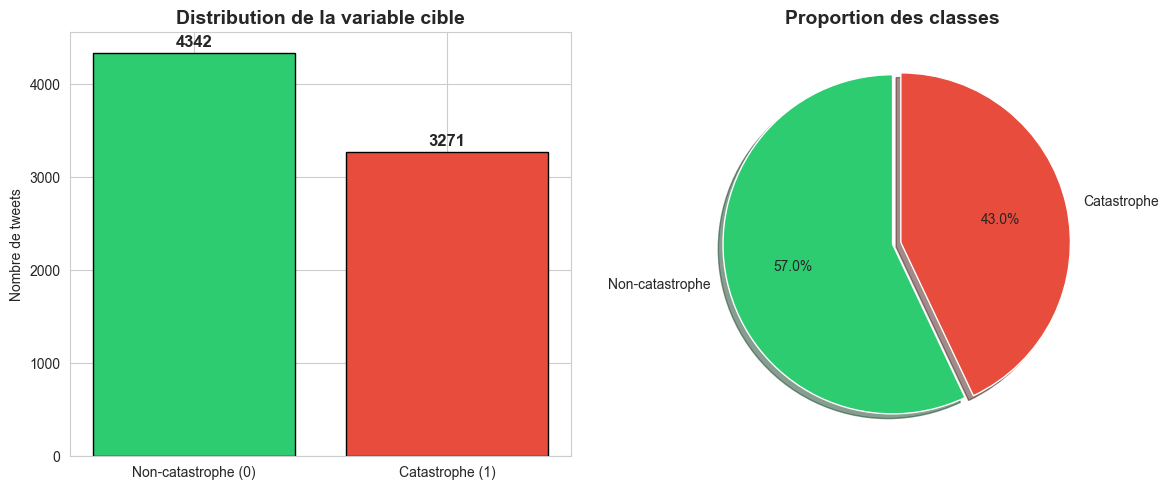

In [5]:
# Distribution de la variable target (uniquement dans le train set)
if 'target' in train_df.columns:
    target_counts = train_df['target'].value_counts()
    print("Distribution de la variable cible :")
    print(f"  Catastrophe (1) : {target_counts.get(1, 0)} tweets ({target_counts.get(1, 0)/len(train_df)*100:.1f}%)")
    print(f"  Non-catastrophe (0) : {target_counts.get(0, 0)} tweets ({target_counts.get(0, 0)/len(train_df)*100:.1f}%)")
    
    # Visualisation
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    
    # Bar plot
    colors = ['#2ecc71', '#e74c3c']
    bars = ax[0].bar(['Non-catastrophe (0)', 'Catastrophe (1)'], 
                     [target_counts.get(0, 0), target_counts.get(1, 0)], 
                     color=colors, edgecolor='black')
    ax[0].set_title('Distribution de la variable cible', fontsize=14, fontweight='bold')
    ax[0].set_ylabel('Nombre de tweets')
    for bar, count in zip(bars, [target_counts.get(0, 0), target_counts.get(1, 0)]):
        ax[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30, str(count),
                   ha='center', va='bottom', fontweight='bold', fontsize=12)
    
    # Pie chart
    ax[1].pie([target_counts.get(0, 0), target_counts.get(1, 0)], 
              labels=['Non-catastrophe', 'Catastrophe'], 
              autopct='%1.1f%%', colors=colors, explode=(0, 0.05),
              shadow=True, startangle=90)
    ax[1].set_title('Proportion des classes', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

---

## 3. Analyse des colonnes descriptives

In [7]:
# Valeurs manquantes
print("=== Valeurs manquantes — Train set ===")
print(train_df.isnull().sum())
print("\n% de valeurs manquantes par colonne :")
print((train_df.isnull().mean() * 100).round(2).astype(str) + ' %')

=== Valeurs manquantes — Train set ===
id             0
keyword       61
location    2533
text           0
target         0
dtype: int64

% de valeurs manquantes par colonne :
id            0.0 %
keyword       0.8 %
location    33.27 %
text          0.0 %
target        0.0 %
dtype: object


In [8]:
# Analyse du champ 'keyword' (mot-clé associé au tweet)
if 'keyword' in train_df.columns:
    print(f"Nombre de keywords uniques : {train_df['keyword'].nunique()}")
    print(f"Nombre de keywords manquants : {train_df['keyword'].isnull().sum()}")
    print("\nTop 15 keywords les plus fréquents (train set) :")
    print(train_df['keyword'].value_counts().head(15))

Nombre de keywords uniques : 221
Nombre de keywords manquants : 61

Top 15 keywords les plus fréquents (train set) :
keyword
fatalities     45
deluge         42
armageddon     42
damage         41
body%20bags    41
harm           41
sinking        41
evacuate       40
outbreak       40
fear           40
siren          40
windstorm      40
collided       40
twister        40
hellfire       39
Name: count, dtype: int64


In [9]:
# Analyse du champ 'location' (localisation)
if 'location' in train_df.columns:
    print(f"Nombre de locations uniques : {train_df['location'].nunique()}")
    print(f"Nombre de locations manquants : {train_df['location'].isnull().sum()}")
    print("\nTop 15 locations les plus fréquentes (train set) :")
    print(train_df['location'].value_counts().head(15))

Nombre de locations uniques : 3341
Nombre de locations manquants : 2533

Top 15 locations les plus fréquentes (train set) :
location
USA                104
New York            71
United States       50
London              45
Canada              29
Nigeria             28
UK                  27
Los Angeles, CA     26
India               24
Mumbai              22
Washington, DC      21
Kenya               20
Worldwide           19
Australia           18
Chicago, IL         18
Name: count, dtype: int64


---

## 4. Analyse textuelle des tweets

In [10]:
# Statistiques de base sur le texte
train_df['text_length'] = train_df['text'].apply(lambda x: len(str(x)))
train_df['word_count'] = train_df['text'].apply(lambda x: len(str(x).split()))

print("=== Statistiques sur la longueur des tweets ===")
print(f"Longueur moyenne (caractères) : {train_df['text_length'].mean():.1f}")
print(f"Longueur médiane (caractères) : {train_df['text_length'].median():.0f}")
print(f"Nombre moyen de mots : {train_df['word_count'].mean():.1f}")
print(f"Nombre médian de mots : {train_df['word_count'].median():.0f}")
print(f"Tweet le plus court : {train_df['text_length'].min()} caractères")
print(f"Tweet le plus long : {train_df['text_length'].max()} caractères")

=== Statistiques sur la longueur des tweets ===
Longueur moyenne (caractères) : 101.2
Longueur médiane (caractères) : 107
Nombre moyen de mots : 14.9
Nombre médian de mots : 15
Tweet le plus court : 7 caractères
Tweet le plus long : 157 caractères


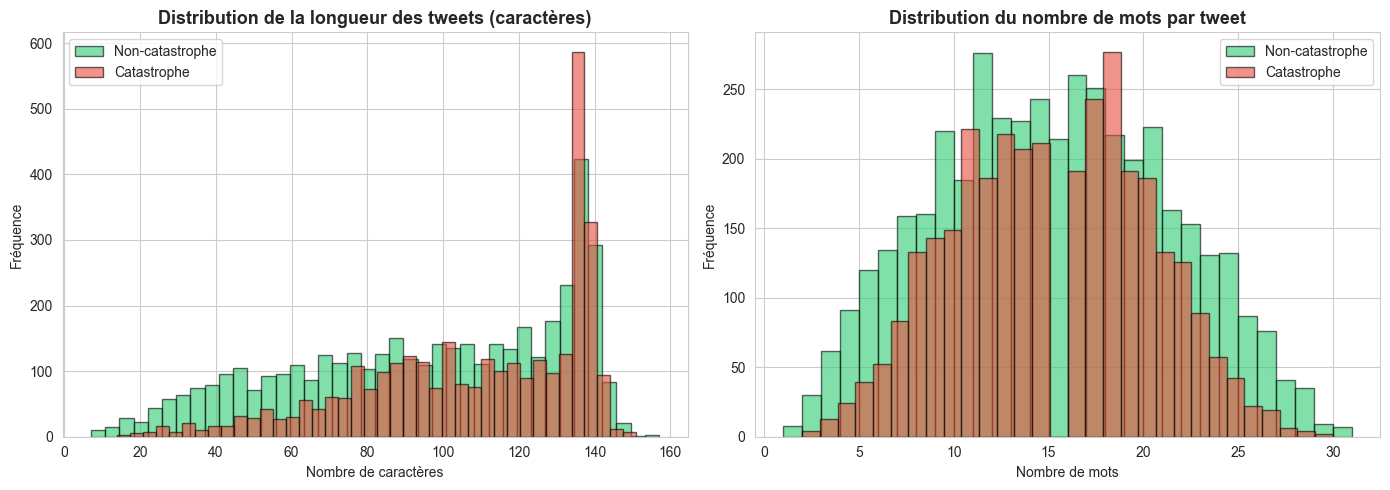

In [11]:
# Distribution de la longueur des tweets par classe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Longueur en caractères
for target_val, label, color in [(0, 'Non-catastrophe', '#2ecc71'), (1, 'Catastrophe', '#e74c3c')]:
    subset = train_df[train_df['target'] == target_val]['text_length']
    axes[0].hist(subset, bins=40, alpha=0.6, label=label, color=color, edgecolor='black')
axes[0].set_title('Distribution de la longueur des tweets (caractères)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Nombre de caractères')
axes[0].set_ylabel('Fréquence')
axes[0].legend()

# Nombre de mots
for target_val, label, color in [(0, 'Non-catastrophe', '#2ecc71'), (1, 'Catastrophe', '#e74c3c')]:
    subset = train_df[train_df['target'] == target_val]['word_count']
    axes[1].hist(subset, bins=30, alpha=0.6, label=label, color=color, edgecolor='black')
axes[1].set_title('Distribution du nombre de mots par tweet', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Nombre de mots')
axes[1].set_ylabel('Fréquence')
axes[1].legend()

plt.tight_layout()
plt.show()

In [12]:
# Mots les plus fréquents (toutes classes confondues)
from collections import Counter

def get_most_common_words(text_series, n=20):
    """Retourne les n mots les plus fréquents dans une série de textes."""
    all_words = []
    for text in text_series.dropna():
        words = re.findall(r'\b[a-zA-Z]+\b', str(text).lower())
        all_words.extend(words)
    return Counter(all_words).most_common(n)

print("Top 20 mots les plus fréquents (hors stop-words) — Classe Catastrophe (1) :")
disaster_words = get_most_common_words(train_df[train_df['target'] == 1]['text'])
for word, count in disaster_words:
    print(f"  {word}: {count}")

print("\nTop 20 mots les plus fréquents (hors stop-words) — Classe Non-catastrophe (0) :")
non_disaster_words = get_most_common_words(train_df[train_df['target'] == 0]['text'])
for word, count in non_disaster_words:
    print(f"  {word}: {count}")

Top 20 mots les plus fréquents (hors stop-words) — Classe Catastrophe (1) :
  t: 2659
  co: 2528
  http: 2382
  the: 1364
  in: 1164
  a: 935
  of: 928
  to: 757
  and: 506
  on: 420
  for: 401
  i: 387
  s: 361
  is: 352
  at: 308
  by: 278
  from: 245
  it: 240
  that: 210
  with: 192

Top 20 mots les plus fréquents (hors stop-words) — Classe Non-catastrophe (0) :
  t: 2540
  co: 2212
  http: 1927
  the: 1913
  i: 1391
  a: 1265
  to: 1192
  and: 920
  of: 902
  in: 822
  you: 757
  is: 598
  s: 549
  my: 546
  it: 539
  for: 493
  on: 440
  that: 413
  with: 380
  this: 298


In [13]:
# Hashtags les plus fréquents
def extract_hashtags(text_series):
    """Extrait les hashtags d'une série de textes."""
    hashtags = []
    for text in text_series.dropna():
        tags = re.findall(r'#(\w+)', str(text))
        hashtags.extend(tags)
    return Counter(hashtags).most_common(15)

print("Top 15 hashtags — Classe Catastrophe (1) :")
for tag, count in extract_hashtags(train_df[train_df['target'] == 1]['text']):
    print(f"  #{tag}: {count}")

print("\nTop 15 hashtags — Classe Non-catastrophe (0) :")
for tag, count in extract_hashtags(train_df[train_df['target'] == 0]['text']):
    print(f"  #{tag}: {count}")

Top 15 hashtags — Classe Catastrophe (1) :
  #News: 33
  #news: 23
  #Hiroshima: 21
  #hot: 13
  #prebreak: 13
  #best: 13
  #Japan: 10
  #India: 10
  #yyc: 10
  #Sismo: 9
  #earthquake: 8
  #abstorm: 8
  #terrorism: 8
  #ISIS: 8
  #BBC: 7

Top 15 hashtags — Classe Non-catastrophe (0) :
  #hot: 18
  #prebreak: 17
  #best: 17
  #news: 15
  #GBBO: 13
  #islam: 11
  #NowPlaying: 10
  #nowplaying: 10
  #jobs: 9
  #EDM: 8
  #DnB: 8
  #Beyhive: 8
  #Directioners: 8
  #RT: 7
  #Dubstep: 7


---

## 5. Exemples de tweets par classe

In [14]:
# Quelques tweets de catastrophe (target = 1)
print("=== Exemples de tweets Catastrophe (target = 1) ===\n")
for i, row in train_df[train_df['target'] == 1].sample(5, random_state=42).iterrows():
    print(f"  [{row['id']}] {row['text'][:150]}")
    print()

print("=== Exemples de tweets Non-catastrophe (target = 0) ===\n")
for i, row in train_df[train_df['target'] == 0].sample(5, random_state=42).iterrows():
    print(f"  [{row['id']}] {row['text'][:150]}")
    print()

=== Exemples de tweets Catastrophe (target = 1) ===

  [5692] Nearly 50 thousand people affected by floods in #Paraguay ? http://t.co/aw23wXtyjB http://t.co/ABgct9VFUa

  [471] Vladimir Putin Issues Major Warning But Is It Too Late To Escape Armageddon?
http://t.co/gBxafy1m1C

  [1753] @DoctorFluxx @StefanEJones @spinnellii @themermacorn  No burning buildings and rob during a riot. That's embarrassing &amp; ruining this nation.

  [716] Telnet attacked from 124.13.172.40 (STREAMYX-HOME-SOUTHERN MY)

  [4253] LONDON IS DROWNING AND IIII LIVE BY THE RIVEEEEEER

=== Exemples de tweets Non-catastrophe (target = 0) ===

  [5260] Everyday is a near death fatality for me on the road. Thank god is on my side.??

  [5937] #Lifestyle Û÷It makes me sickÛª: Baby clothes deemed a Û÷hazardÛª http://t.co/0XrfVidxA2 http://t.co/oIHwgEZDCk

  [6586] @Lenn_Len Probably. We are inundated with them most years!

  [8753] A demoness with the voice of an angel. Like a siren's call beckoning me to the voi

---

## 6. Prochaines étapes (à compléter)

- [ ] Nettoyage des données textuelles (ponctuation, caractères spéciaux, URLs, mentions)
- [ ] Tokenisation et prétraitement (stop-words, stemming/lemmatisation)
- [ ] Vectorisation (Bag of Words, TF-IDF)
- [ ] Modélisation et évaluation
- [ ] Analyse des erreurs de prédiction